# 02 — Analysis: Q1 and Q2

Các code cells tạo bảng, ước lượng và biểu đồ để nhóm kiểm tra. Chủ sở hữu tự viết phần trả lời/diễn giải sau khi review bằng chứng, theo quy định học thuật của môn.

## Q1 — URL structure complexity and label

**Chủ sở hữu:** Tiết Trọng Khiêm — 24127058

**Câu hỏi:** Độ phức tạp cấu trúc URL có khác giữa phishing và benign khi so sánh trong các nhóm độ dài URL tương đương không?

**Động lực, người dùng kết quả và quyết định liên quan:** `[chủ sở hữu tự viết]`

**Biến dẫn xuất dùng trong code:** số loại tín hiệu cấu trúc hiện diện trong URL (subdomain, path, query, IP host, ký tự đặc biệt, `=`, `?`, `&`, nhiều dấu chấm). Mỗi tín hiệu đóng góp 0/1; score nằm trong khoảng 0–9. Đây là quy tắc vận hành cần chủ sở hữu đánh giá/giải thích. So sánh được phân tầng theo quintile độ dài; bootstrap lấy hostname làm cluster.

**Chủ sở hữu bổ sung:** công thức/giả định đã chốt, lý do chọn phương pháp và phần trả lời câu hỏi.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

starts = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in starts if (p / "environment.yml").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate repository root containing environment.yml.")
sys.path.insert(0, str(PROJECT_ROOT))
from src.data_io import load_raw_csv
from src.url_utils import url_structure_complexity

main_raw = load_raw_csv("vn_compphish.csv")
analysis = main_raw.copy()
analysis["label_name"] = analysis["label"].map({0: "benign", 1: "phishing"})
print("Input rows:", len(analysis))

Input rows: 53116


In [2]:
def make_length_bins(series, q=5):
    """Quantile groups; duplicate cut points are collapsed by pandas."""
    return pd.qcut(series, q=q, labels=False, duplicates="drop").astype("Int64")

def make_tld_groups(frame, min_count=100):
    values = frame["tld"].fillna("[Missing]").astype(str)
    counts = values.value_counts()
    return values.where(values.eq("[Missing]") | values.map(counts).ge(min_count), "Other")

def cluster_bootstrap_standardized_difference(data, exposure, positive, negative, outcome, strata, cluster, n_boot=120, seed=2026):
    """Standardized mean/rate difference with a cluster bootstrap CI."""
    columns = [exposure, outcome, cluster, *strata]
    d = data[columns].dropna().copy()
    cell_cols = [*strata, exposure]
    baseline = d.groupby(cell_cols, observed=True)[outcome].agg(["mean", "size"]).reset_index()
    wide = baseline.pivot(index=strata, columns=exposure, values="mean")
    counts = d.groupby(strata, observed=True).size()
    common = wide.dropna(subset=[positive, negative]).index
    if len(common) == 0:
        return {"estimate": np.nan, "ci_low": np.nan, "ci_high": np.nan,
                "common_strata": 0, "rows_in_common_support": 0, "rows": len(d)}
    weights = counts.reindex(common).astype(float)
    rows_in_common_support = int(weights.sum())
    estimate = float(np.average(wide.loc[common, positive] - wide.loc[common, negative], weights=weights))

    clustered = d.groupby([cluster, *cell_cols], observed=True)[outcome].agg(value_sum="sum", value_n="size").reset_index()
    cluster_values = pd.Index(clustered[cluster].drop_duplicates())
    cluster_index = cluster_values.get_indexer(clustered[cluster])
    rng = np.random.default_rng(seed)
    boot = []
    for _ in range(n_boot):
        multiplicity = np.bincount(rng.integers(0, len(cluster_values), size=len(cluster_values)), minlength=len(cluster_values))
        weighted = clustered.assign(w_sum=clustered["value_sum"].to_numpy() * multiplicity[cluster_index],
                                    w_n=clustered["value_n"].to_numpy() * multiplicity[cluster_index])
        grouped = weighted.groupby(cell_cols, observed=True)[["w_sum", "w_n"]].sum()
        grouped["mean"] = grouped["w_sum"] / grouped["w_n"].replace(0, np.nan)
        boot_wide = grouped["mean"].unstack(exposure)
        if positive not in boot_wide or negative not in boot_wide:
            continue
        boot_wide = boot_wide.reindex(common)
        available = boot_wide[[positive, negative]].dropna().index
        if len(available) == 0:
            continue
        boot_weights = weights.reindex(available)
        boot.append(float(np.average(boot_wide.loc[available, positive] - boot_wide.loc[available, negative], weights=boot_weights)))
    low, high = np.quantile(boot, [0.025, 0.975]) if boot else (np.nan, np.nan)
    return {"estimate": estimate, "ci_low": float(low), "ci_high": float(high),
            "common_strata": len(common), "rows_in_common_support": rows_in_common_support, "rows": len(d)}

analysis["complexity_score"] = url_structure_complexity(analysis)
analysis["length_bin"] = make_length_bins(analysis["url_len"], q=5)
q1_input_n = len(analysis)
q1 = analysis.dropna(subset=["complexity_score", "length_bin", "label_name", "dom"]).copy()
print(f"Q1 rows before/after required-field check: {q1_input_n:,} → {len(q1):,}")
print("URL counts by length bin and label:")
display(pd.crosstab(q1["length_bin"], q1["label_name"], margins=True))

Q1 rows before/after required-field check: 53,116 → 53,116
URL counts by length bin and label:


label_name,benign,phishing,All
length_bin,,,
0,4053,8125,12178
1,2817,10240,13057
2,1338,6087,7425
3,2783,8044,10827
4,5419,4210,9629
All,16410,36706,53116


In [3]:
q1_summary = q1.groupby(["length_bin", "label_name"], observed=True).agg(
    url_n=("complexity_score", "size"), mean_complexity=("complexity_score", "mean"),
    median_complexity=("complexity_score", "median")
).reset_index()
q1_wide = q1_summary.pivot(index="length_bin", columns="label_name", values="mean_complexity")
q1_counts = q1_summary.pivot(index="length_bin", columns="label_name", values="url_n")
q1_by_bin = pd.DataFrame({
    "benign_n": q1_counts.get("benign"), "phishing_n": q1_counts.get("phishing"),
    "benign_mean": q1_wide.get("benign"), "phishing_mean": q1_wide.get("phishing")
})
q1_by_bin["phishing_minus_benign"] = q1_by_bin["phishing_mean"] - q1_by_bin["benign_mean"]
display(q1_by_bin.round(3))
q1_effect = cluster_bootstrap_standardized_difference(
    q1, exposure="label_name", positive="phishing", negative="benign",
    outcome="complexity_score", strata=["length_bin"], cluster="dom", n_boot=160, seed=27
)
print("Length-standardized mean score difference (phishing − benign), domain-cluster bootstrap:")
display(pd.DataFrame([q1_effect]).round(4))

,benign_n,phishing_n,benign_mean,phishing_mean,phishing_minus_benign
length_bin,,,,,
0,4053,8125,1.140,1.055,-0.085
1,2817,10240,1.239,2.035,0.796
2,1338,6087,1.415,2.366,0.951
3,2783,8044,2.142,2.442,0.300
4,5419,4210,2.864,2.567,-0.298


Length-standardized mean score difference (phishing − benign), domain-cluster bootstrap:


,estimate,ci_low,ci_high,common_strata,rows_in_common_support,rows
0,0.3165,0.2823,0.3573,5,53116,53116


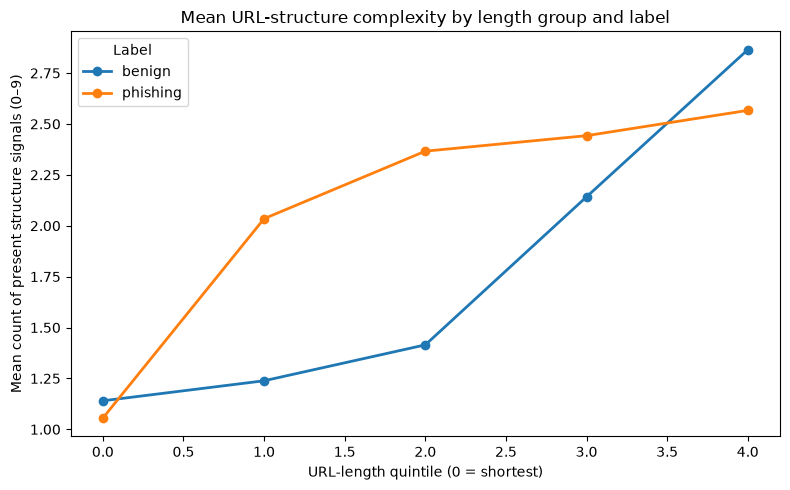

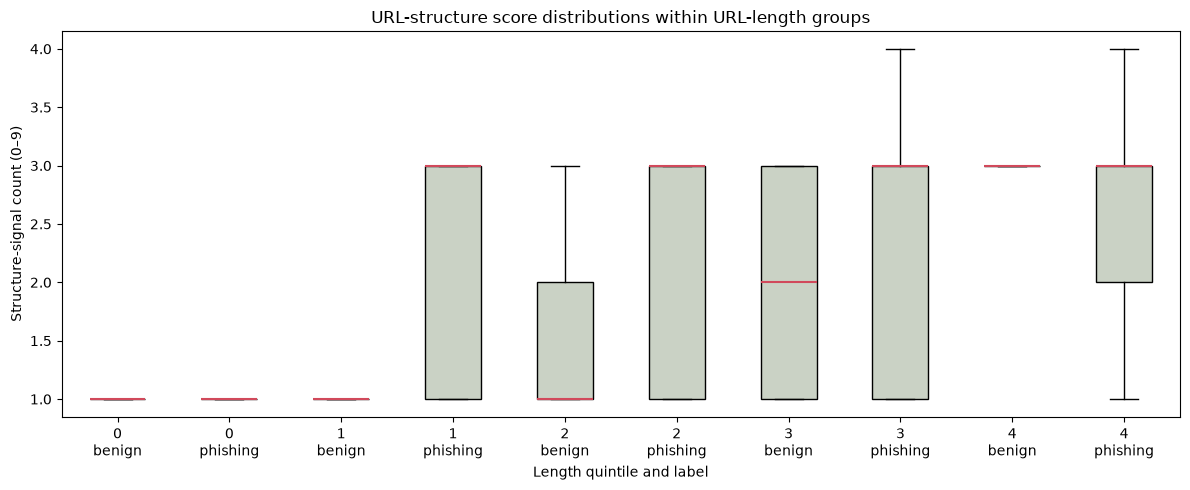

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
for label_name, group in q1_summary.groupby("label_name"):
    ax.plot(group["length_bin"].astype(int), group["mean_complexity"], marker="o", linewidth=2, label=label_name)
ax.set_title("Mean URL-structure complexity by length group and label")
ax.set_xlabel("URL-length quintile (0 = shortest)")
ax.set_ylabel("Mean count of present structure signals (0–9)")
ax.legend(title="Label")
fig.tight_layout()
plt.show()

box_data, box_labels = [], []
for length_bin in sorted(q1["length_bin"].dropna().unique()):
    for label_name in ("benign", "phishing"):
        values = q1.loc[(q1["length_bin"] == length_bin) & (q1["label_name"] == label_name), "complexity_score"]
        box_data.append(values.to_numpy())
        box_labels.append(f"{int(length_bin)}\n{label_name}")
fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot(box_data, showfliers=False, patch_artist=True,
           boxprops={"facecolor": "#cad2c5"}, medianprops={"color": "#d1495b", "linewidth": 1.5})
ax.set_title("URL-structure score distributions within URL-length groups")
ax.set_xlabel("Length quintile and label")
ax.set_ylabel("Structure-signal count (0–9)")
ax.set_xticklabels(box_labels, rotation=0)
fig.tight_layout()
plt.show()

### Q1 — nhóm hoàn thiện

- Công thức/giả định đã được nhóm chốt: `[tự viết]`
- Phương pháp và lý do phù hợp: `[tự viết]`
- Động lực, người dùng kết quả và quyết định liên quan: `[tự viết]`
- Trả lời Q1 bằng kết quả và độ bất định ở trên: `[tự viết]`
- Ý nghĩa, hạn chế và quan sát bất ngờ: `[tự viết]`

## Q2 — HTTPS, TLD and URL length

**Chủ sở hữu:** Tiết Trọng Khiêm — 24127058

**Câu hỏi:** Việc sử dụng HTTPS có liên quan đến nhãn phishing khác biệt thế nào sau khi xét nhóm TLD và độ dài URL?

**Động lực, người dùng kết quả và quyết định liên quan:** `[chủ sở hữu tự viết]`

`is_https` được nguồn giữ lại để tương thích schema và đánh dấu là collection artifact. Code dưới đây chỉ tính liên hệ quan sát được, không suy ra tác động nhân quả. Phân tích chuẩn hóa tỷ lệ phishing trong các strata TLD × độ dài có cả hai giá trị HTTPS; khoảng tin cậy bootstrap lấy `dom` làm cluster. Hai ngưỡng gộp TLD hiếm được dùng làm robustness check. Chủ sở hữu cần giải thích lựa chọn cuối cùng và phạm vi diễn giải.

In [5]:
def run_q2_threshold(data, tld_min_count, length_q=5, n_boot=100, seed=2026):
    d = data.copy()
    d["tld_group"] = make_tld_groups(d, min_count=tld_min_count)
    d["length_bin"] = make_length_bins(d["url_len"], q=length_q)
    before = len(d)
    d = d.dropna(subset=["label", "is_https", "tld_group", "length_bin", "dom"]).copy()
    result = cluster_bootstrap_standardized_difference(
        d, exposure="is_https", positive=1, negative=0, outcome="label",
        strata=["tld_group", "length_bin"], cluster="dom", n_boot=n_boot, seed=seed + tld_min_count
    )
    result.update({"rare_tld_min_n": tld_min_count, "length_bins": int(d["length_bin"].nunique()),
                   "rows_before": before, "rows_after": len(d)})
    return result, d

q2_results = []
q2_data = None
for threshold in (50, 100, 500):
    result, current = run_q2_threshold(analysis, threshold, length_q=5, n_boot=100)
    q2_results.append(result)
    if threshold == 100:
        q2_data = current
q2_effects = pd.DataFrame(q2_results)
q2_effects["rows_outside_common_support"] = q2_effects["rows_after"] - q2_effects["rows_in_common_support"]
q2_effects = q2_effects[["rare_tld_min_n", "estimate", "ci_low", "ci_high", "common_strata",
                         "rows_before", "rows_after", "rows_in_common_support", "rows_outside_common_support"]]
print("Standardized phishing-rate difference (HTTPS=1 minus HTTPS=0); domain-cluster bootstrap 95% percentile interval")
print("Rows outside common support are excluded from the standardized contrast; full-sample counts remain visible.")
display(q2_effects.round(4))
print("Q2 phishing rates by TLD group and HTTPS state; URL-length adjustment is summarized above")
display(q2_data.groupby(["tld_group", "is_https"], observed=True)["label"].agg(["size", "mean"]).rename(columns={"size": "url_n", "mean": "phishing_rate"}).round(4))

Standardized phishing-rate difference (HTTPS=1 minus HTTPS=0); domain-cluster bootstrap 95% percentile interval
Rows outside common support are excluded from the standardized contrast; full-sample counts remain visible.


,rare_tld_min_n,estimate,ci_low,ci_high,common_strata,rows_before,rows_after,rows_in_common_support,rows_outside_common_support
0,50,-0.4397,-0.4889,-0.4102,59,53116,53116,38510,14606
1,100,-0.4353,-0.4884,-0.3999,52,53116,53116,39395,13721
2,500,-0.4090,-0.4811,-0.3845,40,53116,53116,44259,8857


Q2 phishing rates by TLD group and HTTPS state; URL-length adjustment is summarized above


url_n  phishing_rate
tld_group is_https                      
Other     0          3780         0.5450
          1            92         0.8913
[Missing] 0             2         1.0000
app       0           138         0.8623
          1            26         1.0000
...                   ...            ...
vn        0          2889         0.2527
          1           106         0.0000
win       0           199         0.9899
xyz       0          2567         0.9856
          1             3         1.0000

[63 rows x 2 columns]

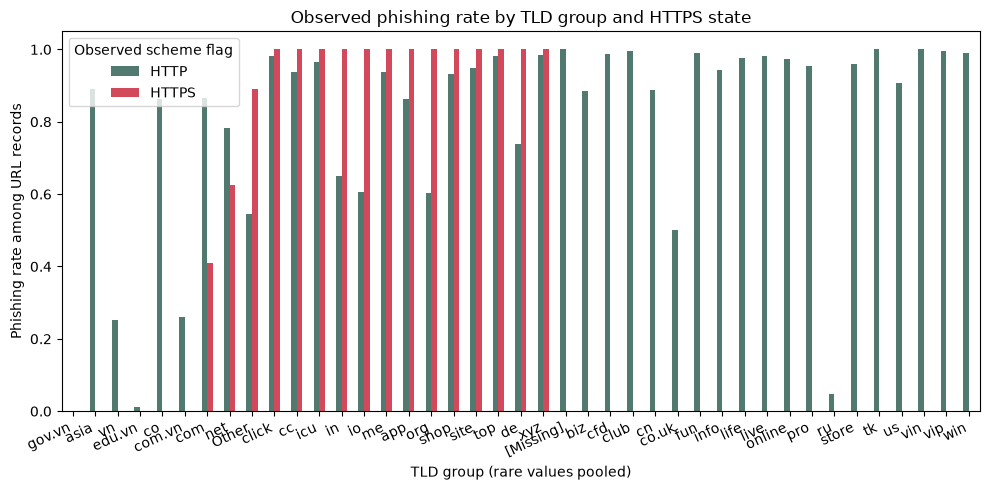

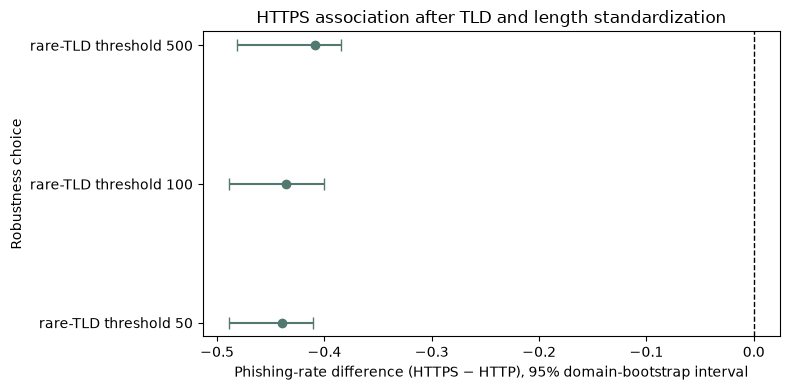

In [6]:
q2_rates = q2_data.groupby(["tld_group", "is_https"], observed=True)["label"].mean().unstack("is_https")
q2_rates = q2_rates.rename(columns={0: "HTTP", 1: "HTTPS"})
q2_rates = q2_rates.sort_values(by="HTTPS" if "HTTPS" in q2_rates.columns else q2_rates.columns[-1])
ax = q2_rates.plot(kind="bar", figsize=(10, 5), color=["#52796f", "#d1495b"])
ax.set_title("Observed phishing rate by TLD group and HTTPS state")
ax.set_xlabel("TLD group (rare values pooled)")
ax.set_ylabel("Phishing rate among URL records")
ax.legend(title="Observed scheme flag")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for i, row in q2_effects.reset_index(drop=True).iterrows():
    estimate, low, high = row["estimate"], row["ci_low"], row["ci_high"]
    ax.errorbar(estimate, i, xerr=[[estimate - low], [high - estimate]], fmt="o", capsize=4, color="#52796f")
ax.axvline(0, color="black", linewidth=1, linestyle="--")
ax.set_yticks(range(len(q2_effects)), [f"rare-TLD threshold {v}" for v in q2_effects["rare_tld_min_n"]])
ax.set_title("HTTPS association after TLD and length standardization")
ax.set_xlabel("Phishing-rate difference (HTTPS − HTTP), 95% domain-bootstrap interval")
ax.set_ylabel("Robustness choice")
fig.tight_layout()
plt.show()

### Q2 — nhóm hoàn thiện

- Biến HTTPS và các trường hợp không xác định: `[tự viết]`
- Cách chọn/gộp TLD và nhóm độ dài: `[tự viết]`
- Động lực, người dùng kết quả và quyết định liên quan: `[tự viết]`
- Trả lời Q2 bằng ước lượng và khoảng bất định ở trên: `[tự viết]`
- Robustness check và giới hạn do collection artifact: `[tự viết]`